# Backtest report — walk-forward validation of the pricing stack

Produced by `scripts/run_backtest.py` (re-run it to refresh the parquet/CSV this
notebook reads). Setup: for every club match in test seasons 2017/18 → 2025/26 with
closing odds, the production pipeline (odds-anchored Dixon-Coles + count regressions
fitted only on earlier seasons) priced a battery of synthetic questions mirroring the
World Cup market families; each prediction is Brier-scored against reality.

**Baselines**: `brier_50` = always answer 50% (naive crowd); `brier_baserate` = answer the
family's historical frequency (informed crowd). We win where `brier_model` undercuts both.

Key conclusions (see tables below):
- All 19 families beat the 50% guess; 16/19 beat the informed base rate.
- Cards/fouls families carry no team-quality signal (as the literature predicts) —
  their model weight is shrunk via `data/family_blend.json` (w=0.40 for card totals).
- Pooled calibration is within ±1% across the main probability range.

In [1]:
from pathlib import Path

import pandas as pd

DATA = Path.cwd().parent / "data"
results = pd.read_parquet(DATA / "backtest_results.parquet").dropna(subset=["p"])
report = pd.read_csv(DATA / "backtest_report.csv")
print(f"{len(results):,} scored predictions across {results['family'].nunique()} families")
report.style.background_gradient(subset=["edge_vs_baserate"], cmap="RdYlGn").format(precision=4)

782,227 scored predictions across 19 families


,family,n,brier_model,brier_50,brier_baserate,edge_vs_50,edge_vs_baserate
0,more_sot,41165,0.2136,0.2500,0.2493,0.0364,0.0357
1,team_win,41178,0.2164,0.2500,0.2459,0.0336,0.0294
2,more_corners,41165,0.2268,0.2500,0.2488,0.0232,0.0220
3,team_goals_ge2,41178,0.2236,0.2500,0.2454,0.0264,0.0218
4,team_sot_ge4,41165,0.2097,0.2500,0.2301,0.0403,0.0204
5,team_more_goals_2h,41178,0.2171,0.2500,0.2331,0.0329,0.0159
6,ht_team_winning,41178,0.2094,0.2500,0.2234,0.0406,0.0139
7,team_corners_ge5,41165,0.2319,0.2500,0.2454,0.0181,0.0135
8,team_scores_2h,41178,0.2361,0.2500,0.2471,0.0139,0.0109
9,total_sot_ge8,41165,0.2310,0.2500,0.2414,0.0190,0.0104


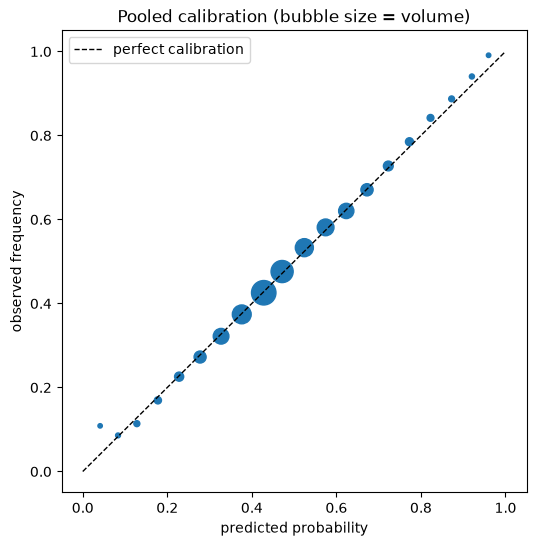

,predicted,actual,n,gap
bucket,,,,
0,0.041,0.109,46,0.068
1,0.083,0.086,1199,0.002
2,0.128,0.114,4415,-0.014
3,0.178,0.169,8442,-0.008
4,0.228,0.226,17043,-0.002
5,0.278,0.273,33459,-0.005
6,0.327,0.322,60355,-0.005
7,0.376,0.374,89536,-0.002
8,0.428,0.426,154167,-0.003


In [2]:
import matplotlib.pyplot as plt

results["bucket"] = (results["p"] * 20).clip(0, 19).astype(int)
cal = results.groupby("bucket").agg(predicted=("p", "mean"), actual=("outcome", "mean"), n=("outcome", "size"))

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.scatter(cal["predicted"], cal["actual"], s=cal["n"] / cal["n"].max() * 300 + 10)
ax.set_xlabel("predicted probability")
ax.set_ylabel("observed frequency")
ax.set_title("Pooled calibration (bubble size = volume)")
ax.legend()
plt.show()

cal["gap"] = cal["actual"] - cal["predicted"]
cal.round(3)

In [3]:
# Stability check: model edge vs the 50% baseline must hold in every season,
# not just on average — a prerequisite for trusting it on 2026 matches.
per_season = results.groupby("season").apply(
    lambda df: pd.Series({
        "n": len(df),
        "brier_model": ((df["p"] - df["outcome"]) ** 2).mean(),
        "brier_50": ((0.5 - df["outcome"]) ** 2).mean(),
    }), include_groups=False)
per_season["edge"] = per_season["brier_50"] - per_season["brier_model"]
per_season.round(4)

,n,brier_model,brier_50,edge
season,,,,
2021,131984.0,0.2321,0.25,0.0179
2122,132109.0,0.2307,0.25,0.0193
2223,130845.0,0.2297,0.25,0.0203
2324,130816.0,0.2286,0.25,0.0214
2425,128546.0,0.2297,0.25,0.0203
2526,127927.0,0.2309,0.25,0.0191
